In [ ]:
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - turn on T4 GPU")

GPU: Tesla T4


In [ ]:
from google.colab import files
uploaded = files.upload()      # click "Choose files" and pick Test.zip

!mkdir -p /content/data
!unzip -q -o /content/Test.zip -d /content/data
!ls /content/data

Saving Test.zip to Test.zip
Test


In [ ]:
!for d in $(find /content/data -mindepth 2 -type d); do echo "$d: $(ls "$d" | wc -l)"; done

/content/data/Test/No_Fire: 3480
/content/data/Test/Fire: 5137


Total test images: 8617


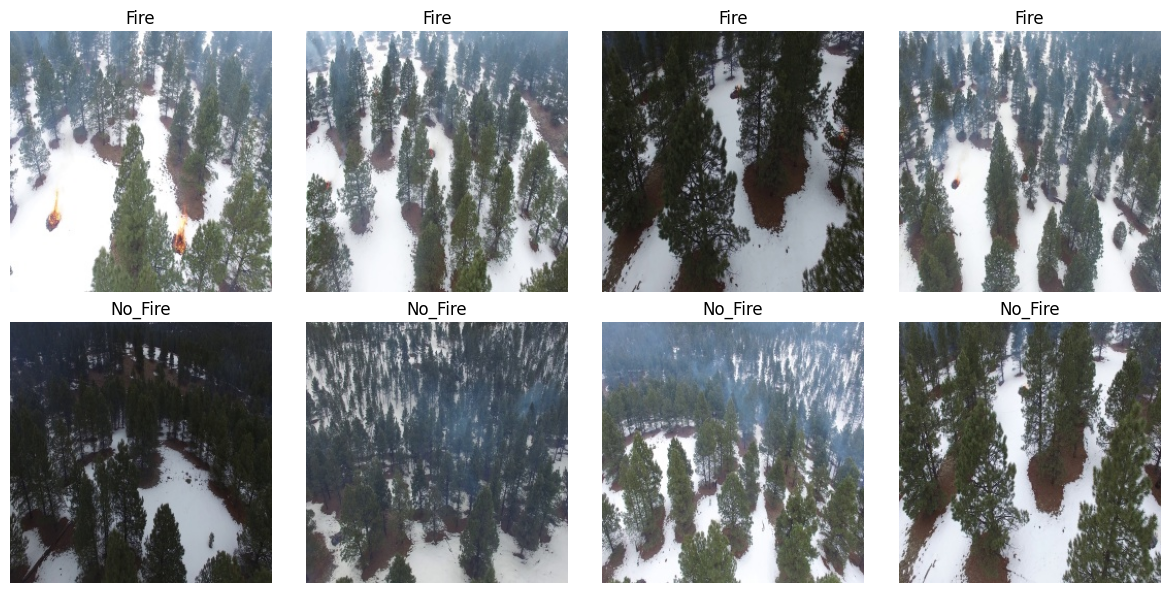

In [ ]:
import glob, numpy as np, matplotlib.pyplot as plt
from PIL import Image

fire_paths   = sorted(glob.glob('/content/data/Test/Fire/*'))
nofire_paths = sorted(glob.glob('/content/data/Test/No_Fire/*'))

test_paths  = fire_paths + nofire_paths
test_labels = np.array([1]*len(fire_paths) + [0]*len(nofire_paths))   # 1 = Fire, 0 = No_Fire
print("Total test images:", len(test_paths))

rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, (paths, name) in enumerate([(fire_paths, 'Fire'), (nofire_paths, 'No_Fire')]):
    for ax, p in zip(axes[row], rng.choice(paths, 4, replace=False)):
        ax.imshow(Image.open(p)); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
!pip install -q open_clip_torch
import open_clip, torch

device = 'cuda'
model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
tokenizer = open_clip.get_tokenizer('ViT-B-32')
model = model.to(device).eval()
print("CLIP is ready")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP is ready


In [ ]:
prompts = ["an aerial drone photo of a forest with no fire",
           "an aerial drone photo of a forest fire with flames and smoke"]

with torch.no_grad():
    text = model.encode_text(tokenizer(prompts).to(device))
    text = text / text.norm(dim=-1, keepdim=True)

def ask_clip(path):
    img = preprocess(Image.open(path).convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        f = model.encode_image(img)
        f = f / f.norm(dim=-1, keepdim=True)
        probs = (100 * f @ text.T).softmax(dim=-1)[0]
    return probs[1].item()    # CLIP's probability that it's Fire

for p, true in [(fire_paths[0], 'Fire'), (nofire_paths[0], 'No_Fire')]:
    plt.imshow(Image.open(p)); plt.axis('off'); plt.show()
    print(f"True label: {true}  |  CLIP says P(Fire) = {ask_clip(p):.2f}\n")

# FLAME Wildfire Detection — CLIP Zero-Shot & Few-Shot

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then run the cells top to bottom.

Steps:
1. Check GPU
2. Point to your zip file(s) and unzip
3. Find the Fire / No_Fire folders automatically
4. Load CLIP and compute image embeddings (once, cached to Drive)
5. Zero-shot classification (no labels)
6. Few-shot classification (10–100 labels per class)
7. Plot and save results

## 1. Check the GPU

In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ No GPU. Go to Runtime → Change runtime type → T4 GPU, then rerun.")

GPU available: True
GPU: Tesla T4


In [ ]:
import shutil
shutil.make_archive('/content/FLAME_results', 'zip', SAVE_DIR)
files.download('/content/FLAME_results.zip')

## 2. Find and unzip your data

**Option A — zip is in Google Drive:** run the mount cell, then set the path in the next cell.

**Option B — you uploaded the zip into Colab's file panel (left sidebar):** skip the mount cell; the zip will be in `/content/`.

The next cell lists every zip it can find so you can copy the exact path.

In [ ]:
# Mount Google Drive (skip if your zip is already in /content)
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

ValueError: Mountpoint must not already contain files

In [ ]:
import glob
zips = glob.glob('/content/*.zip') + glob.glob('/content/drive/MyDrive/Vision AI Project/**/*.zip', recursive=True)
print("Zip files found:")
for z in zips:
    print("  ", z)

Zip files found:


👉 **Edit the list below** — paste the path(s) of your zip(s) from the output above.

On IEEE DataPort the classification data usually comes as two zips: `Training.zip` and `Test.zip`. If you have one big zip, just list that one.

In [ ]:
ZIP_PATHS = [
    '/content/drive/MyDrive/Vision AI Project/Training.zip',
    '/content/drive/MyDrive/Vision AI Project/Test.zip',
]
SAVE_DIR = '/content/drive/MyDrive/Vision AI Project/FLAME_results'

In [ ]:
import os, zipfile

DATA_DIR = '/content/data'   # unzip to Colab's local disk (much faster than reading from Drive)
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(SAVE_DIR, exist_ok=True)

for zp in ZIP_PATHS:
    print("Unzipping", zp, "...")
    with zipfile.ZipFile(zp) as z:
        z.extractall(DATA_DIR)
print("Done. Top-level contents of", DATA_DIR, ":", os.listdir(DATA_DIR))

Unzipping /content/drive/MyDrive/Vision AI Project/Training.zip ...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Vision AI Project/Training.zip'

## 3. Find the Fire / No_Fire folders and build image lists

This walks through whatever the zip created and finds folders named `Fire` and `No_Fire`. It decides train vs test from the parent folder name (anything containing "train" or "test").

In [ ]:
from pathlib import Path

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp'}

def find_split(split_word):
    paths, labels = [], []
    for d in Path(DATA_DIR).rglob('*'):
        if not d.is_dir():
            continue
        name = d.name.lower().replace('-', '_').replace(' ', '_')
        if name not in ('fire', 'no_fire', 'nofire'):
            continue
        if split_word not in str(d.parent).lower():
            continue
        label = 1 if name == 'fire' else 0
        files = sorted(p for p in d.iterdir() if p.suffix.lower() in IMG_EXT)
        paths += [str(p) for p in files]
        labels += [label] * len(files)
        print(f"  {d}  ->  {len(files)} images  (label={label})")
    return paths, labels

print("TRAIN folders:")
train_paths, train_labels = find_split('train')
print("TEST folders:")
test_paths, test_labels = find_split('test')

import numpy as np
train_labels, test_labels = np.array(train_labels), np.array(test_labels)
print(f"\nTrain: {len(train_paths)} images, {train_labels.sum()} Fire, {(train_labels==0).sum()} No_Fire")
print(f"Test:  {len(test_paths)} images, {test_labels.sum()} Fire, {(test_labels==0).sum()} No_Fire")
print("Expected roughly: Train 39,375 (25,018 Fire) | Test 8,617 (5,137 Fire)")

⚠️ If either count is 0, run the cell below to see the folder structure and tell me what it prints — the folder names may differ.

In [ ]:
# Show folder structure (first 3 levels)
for root, dirs, files in os.walk(DATA_DIR):
    depth = root[len(DATA_DIR):].count(os.sep)
    if depth > 3:
        continue
    print('  ' * depth + os.path.basename(root) + f'/  ({len(files)} files)')

### Look at a few samples

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, lab in enumerate([1, 0]):
    idx = rng.choice(np.where(train_labels == lab)[0], 4, replace=False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(Image.open(train_paths[i]))
        ax.set_title('Fire' if lab else 'No_Fire')
        ax.axis('off')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/samples.png', dpi=120)
plt.show()

## 4. Load CLIP and compute embeddings

In [ ]:
!pip install -q open_clip_torch

In [ ]:
import open_clip

device = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL_NAME = 'ViT-B-32'
model, _, preprocess = open_clip.create_model_and_transforms(MODEL_NAME, pretrained='openai')
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
model = model.to(device).eval()
print("CLIP loaded on", device)

This step runs every image through CLIP once and saves the result. On a T4 GPU expect roughly 5–10 min for train and 1–2 min for test. If Colab disconnects later, the next run loads the saved files instantly.

In [ ]:
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

class ImageList(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return preprocess(Image.open(self.paths[i]).convert('RGB'))

@torch.no_grad()
def embed_images(paths, cache_file):
    if os.path.exists(cache_file):
        print("Loading cached", cache_file)
        return np.load(cache_file)
    loader = DataLoader(ImageList(paths), batch_size=256, num_workers=2)
    feats = []
    for x in tqdm(loader, desc=os.path.basename(cache_file)):
        f = model.encode_image(x.to(device))
        f = f / f.norm(dim=-1, keepdim=True)
        feats.append(f.cpu().float().numpy())
    feats = np.concatenate(feats)
    np.save(cache_file, feats)
    return feats

train_emb = embed_images(train_paths, f'{SAVE_DIR}/train_emb_{MODEL_NAME}.npy')
test_emb  = embed_images(test_paths,  f'{SAVE_DIR}/test_emb_{MODEL_NAME}.npy')
print("Train embeddings:", train_emb.shape, " Test embeddings:", test_emb.shape)

## 5. Zero-shot classification (no labels at all)

Each prompt pair is `[No_Fire text, Fire text]`. We try several and report each — prompt choice matters a lot for CLIP.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

PROMPT_PAIRS = {
    'simple':      ["a photo of a forest", "a photo of a forest fire"],
    'aerial':      ["an aerial drone photo of a forest with no fire",
                    "an aerial drone photo of a forest fire with flames and smoke"],
    'flames':      ["an aerial view of pine trees and snow",
                    "an aerial view of burning flames"],
    'wildfire':    ["a drone image of a normal forest", "a drone image of a wildfire"],
    'smoke_fire':  ["a clear aerial image of trees",
                    "an aerial image of fire and smoke in a forest"],
}

@torch.no_grad()
def text_features(prompts):
    t = model.encode_text(tokenizer(prompts).to(device))
    return (t / t.norm(dim=-1, keepdim=True)).cpu().float().numpy()

def metrics(y_true, p_fire, thr=0.5):
    y_pred = (p_fire >= thr).astype(int)
    return dict(accuracy=accuracy_score(y_true, y_pred),
                f1=f1_score(y_true, y_pred),
                auc=roc_auc_score(y_true, p_fire))

zs_rows = []
for name, prompts in PROMPT_PAIRS.items():
    logits = 100 * test_emb @ text_features(prompts).T
    probs = np.exp(logits - logits.max(1, keepdims=True))
    probs /= probs.sum(1, keepdims=True)
    m = metrics(test_labels, probs[:, 1])
    zs_rows.append({'prompt_set': name, **m})

import pandas as pd
zs_df = pd.DataFrame(zs_rows).sort_values('f1', ascending=False)
zs_df.to_csv(f'{SAVE_DIR}/zero_shot_results.csv', index=False)
zs_df.round(3)

## 6. Few-shot classification (linear probe)

For each k (labeled images **per class**) we randomly pick k Fire + k No_Fire training images, fit a logistic regression on their CLIP embeddings, and test on the full test set. Repeated with 5 random seeds to get mean ± std.

The last row (`k = all`) uses every training label — an upper bound to compare against your ResNet.

In [ ]:
from sklearn.linear_model import LogisticRegression

K_VALUES = [1, 5, 10, 25, 50, 100]
SEEDS = [0, 1, 2, 3, 4]
fire_idx, nofire_idx = np.where(train_labels == 1)[0], np.where(train_labels == 0)[0]

fs_rows = []
for k in K_VALUES:
    for seed in SEEDS:
        r = np.random.default_rng(seed)
        idx = np.concatenate([r.choice(fire_idx, k, replace=False),
                              r.choice(nofire_idx, k, replace=False)])
        clf = LogisticRegression(max_iter=1000, C=1.0)
        clf.fit(train_emb[idx], train_labels[idx])
        p = clf.predict_proba(test_emb)[:, 1]
        fs_rows.append({'k': k, 'seed': seed, **metrics(test_labels, p)})

# Upper bound: all training labels
clf = LogisticRegression(max_iter=2000, C=1.0, class_weight='balanced')
clf.fit(train_emb, train_labels)
full = metrics(test_labels, clf.predict_proba(test_emb)[:, 1])
print("Linear probe with ALL train labels:", {k: round(v, 3) for k, v in full.items()})

fs_df = pd.DataFrame(fs_rows)
fs_df.to_csv(f'{SAVE_DIR}/few_shot_results_raw.csv', index=False)
fs_summary = fs_df.groupby('k')[['accuracy', 'f1', 'auc']].agg(['mean', 'std']).round(3)
fs_summary.to_csv(f'{SAVE_DIR}/few_shot_results_summary.csv')
fs_summary

## 7. Plot: how many labels does CLIP need?

In [ ]:
best_zs = zs_df.iloc[0]
g = fs_df.groupby('k')['f1']
mean, std = g.mean(), g.std()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(mean.index, mean.values, yerr=std.values, marker='o', capsize=4,
            label='CLIP few-shot (linear probe)')
ax.axhline(best_zs['f1'], ls='--', color='gray',
           label=f"CLIP zero-shot ({best_zs['prompt_set']})")
ax.axhline(full['f1'], ls=':', color='black', label='CLIP linear probe, all labels')
# ax.axhline(RESNET_F1, ls='-.', color='red', label='ResNet (supervised)')  # add once you have it
ax.set_xscale('log')
ax.set_xticks(K_VALUES); ax.set_xticklabels(K_VALUES)
ax.set_xlabel('Labeled images per class (k)')
ax.set_ylabel('Test F1 (Fire)')
ax.set_title('FLAME test set: F1 vs number of labels')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/f1_vs_k.png', dpi=150)
plt.show()

### Optional: confusion matrix for the best zero-shot prompt

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
prompts = PROMPT_PAIRS[best_zs['prompt_set']]
logits = 100 * test_emb @ text_features(prompts).T
pred = logits.argmax(1)
ConfusionMatrixDisplay.from_predictions(test_labels, pred, display_labels=['No_Fire', 'Fire'])
plt.title(f"Zero-shot: {best_zs['prompt_set']}")
plt.savefig(f'{SAVE_DIR}/zero_shot_confusion.png', dpi=150)
plt.show()
print("All results saved in", SAVE_DIR)